# 1.. Introduction to Data & Business Problem !

# 2.. Working with shapefiles !

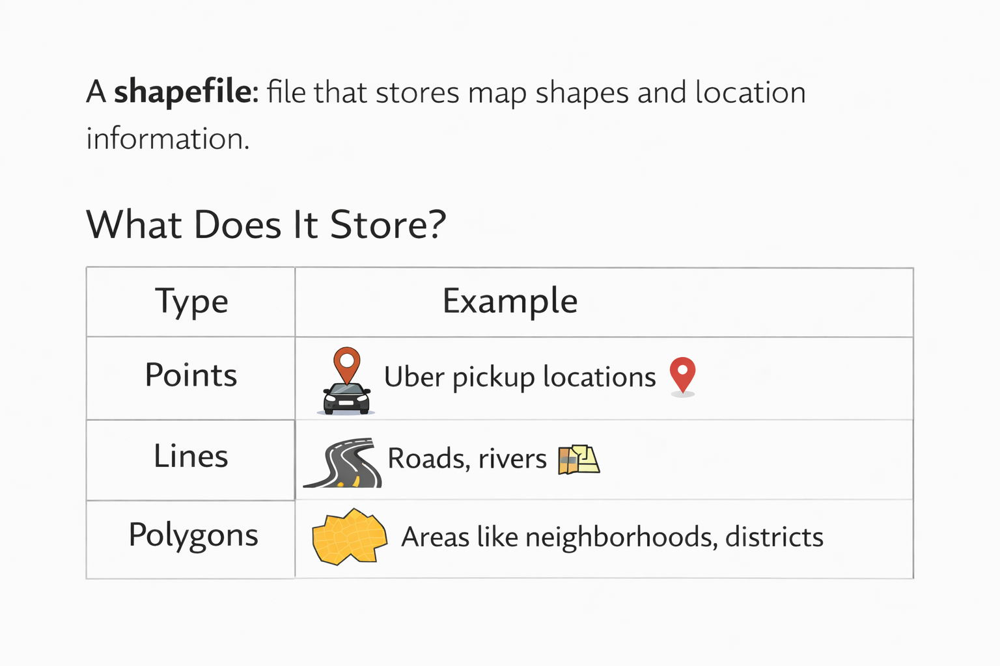

In [1]:
!pip install geopandas

In [2]:
import geopandas as gpd

In [4]:
zones = gpd.read_file(r"R:\All_Datasets\Data_Analysis_Projects\Uber\taxi_zones/taxi_zones.shp")

In [5]:
zones.shape

(263, 7)

In [6]:
zones.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


In [ ]:
'''

This file is a digital map of NYC divided into Uber taxi zones, 
where each row stores the name, borough, ID, and the actual boundary shape of that area


'''

In [ ]:
'''

| Column       | Meaning                  |
| ------------ | ------------------------ |
| `LocationID` | Taxi zone ID             |
| `borough`    | Manhattan, Brooklyn, etc |
| `zone`       | Zone name / neighborhood |
| 'geometry'   | The actual shape of the zone on the map(polygon or multipolygon) 🗺️       |

| **Shape_Leng** | The **perimeter length** of the zone boundary (measured in map units, not very useful for basic analysis) |
| **Shape_Area** | The **area size** of the zone (again in map units, depends on CRS)                                        |



'''

# 3.. Key terms used in Spatial analysis 
       

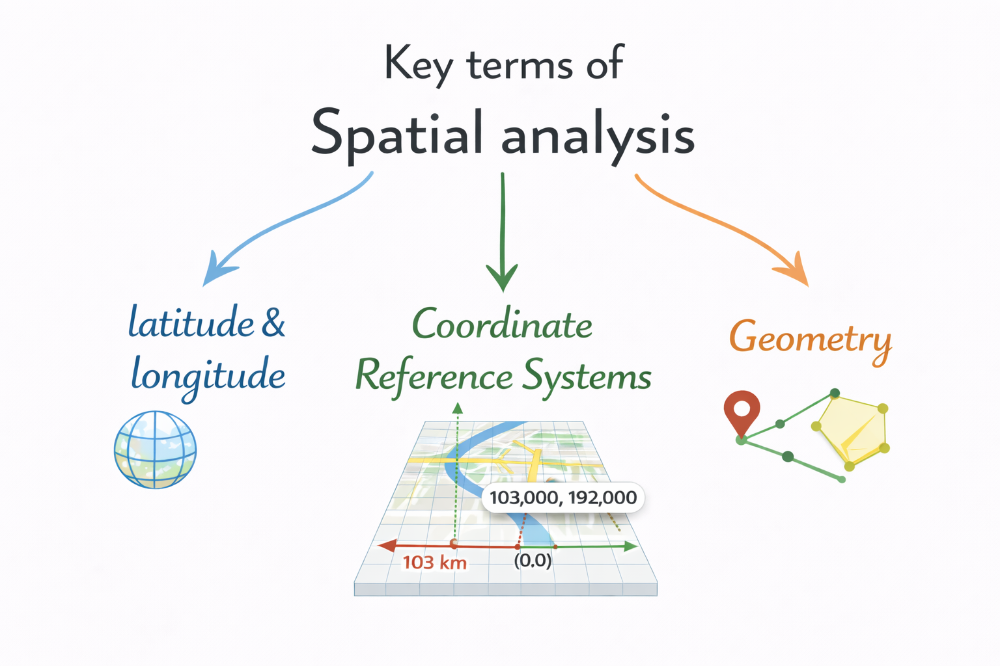

In [8]:
zones  = zones.to_crs(epsg=4326)

In [9]:
zones.head(3)

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((-74.18445 40.695, -74.18449 40.6951,..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((-73.82338 40.63899, -73.82277 ..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((-73.84793 40.87134, -73.84725 40.870..."


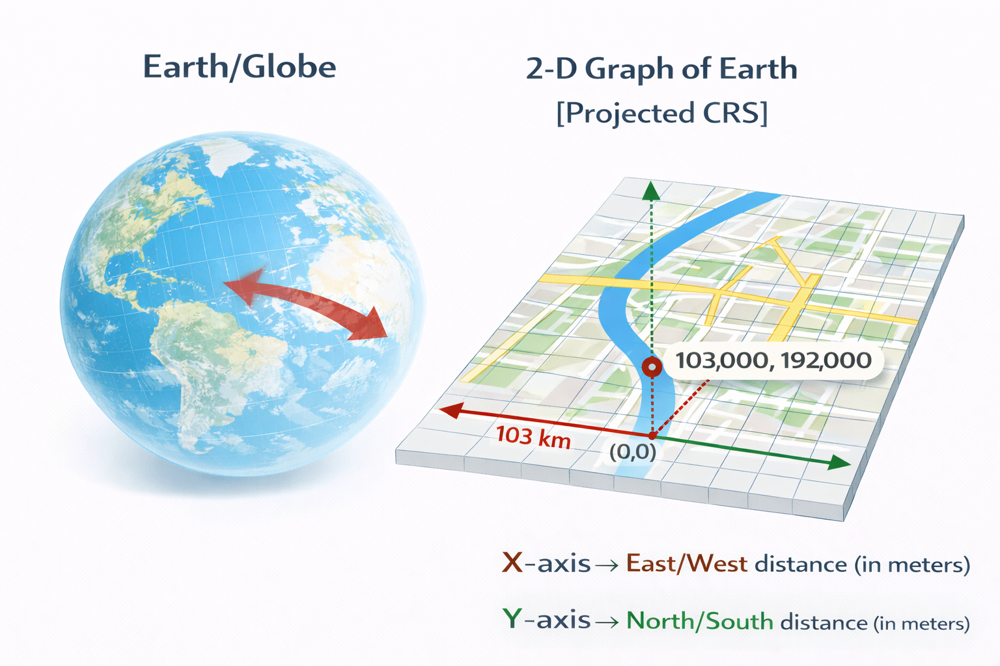

In [10]:
zones.head(2)

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((-74.18445 40.695, -74.18449 40.6951,..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((-73.82338 40.63899, -73.82277 ..."


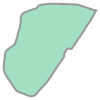

In [11]:
zones["geometry"][0]

# 4.. Analysing Busiest Pickup Zones of Uber !

In [ ]:
!pip install pandas

In [12]:
import pandas as pd

In [13]:
df = pd.read_csv(r"R:\All_Datasets\Data_Analysis_Projects\Uber\Datasets/uber-raw-data-sep14.csv")

In [14]:
df.head(3)

,Date/Time,Lat,Lon,Base
0,9/1/2014 0:01:00,40.2201,-74.0021,B02512
1,9/1/2014 0:01:00,40.7500,-74.0027,B02512
2,9/1/2014 0:03:00,40.7559,-73.9864,B02512


In [ ]:
!pip install shapely

In [15]:
from shapely.geometry import Point

In [16]:
geometry = [Point(xy) for xy in zip(df['Lon'] , df["Lat"])]

In [17]:
geometry

[<POINT (-74.002 40.22)>,
 <POINT (-74.003 40.75)>,
 <POINT (-73.986 40.756)>,
 <POINT (-73.989 40.745)>,
 <POINT (-73.944 40.814)>,
 <POINT (-73.992 40.674)>,
 <POINT (-73.647 40.747)>,
 <POINT (-74.269 40.661)>,
 <POINT (-74 40.374)>,
 <POINT (-73.977 40.763)>,
 <POINT (-73.613 40.747)>,
 <POINT (-73.96 40.81)>,
 <POINT (-74.011 40.679)>,
 <POINT (-73.984 40.402)>,
 <POINT (-74.04 40.738)>,
 <POINT (-73.988 40.721)>,
 <POINT (-73.908 40.865)>,
 <POINT (-74.006 40.74)>,
 <POINT (-74.012 40.679)>,
 <POINT (-73.988 40.733)>,
 <POINT (-73.933 40.674)>,
 <POINT (-73.996 40.764)>,
 <POINT (-73.981 40.764)>,
 <POINT (-73.998 40.742)>,
 <POINT (-73.986 40.744)>,
 <POINT (-73.941 40.661)>,
 <POINT (-73.995 40.749)>,
 <POINT (-74.004 40.753)>,
 <POINT (-74.181 41.032)>,
 <POINT (-73.963 40.798)>,
 <POINT (-73.943 40.693)>,
 <POINT (-74.004 40.707)>,
 <POINT (-74 40.719)>,
 <POINT (-73.986 40.761)>,
 <POINT (-73.943 40.829)>,
 <POINT (-73.987 40.761)>,
 <POINT (-73.984 40.722)>,
 <POINT (-73.98

In [19]:
uber_geo = gpd.GeoDataFrame(df , geometry = geometry , crs = "EPSG:4326")

In [20]:
uber_geo.head(4)

,Date/Time,Lat,Lon,Base,geometry
0,9/1/2014 0:01:00,40.2201,-74.0021,B02512,POINT (-74.0021 40.2201)
1,9/1/2014 0:01:00,40.7500,-74.0027,B02512,POINT (-74.0027 40.75)
2,9/1/2014 0:03:00,40.7559,-73.9864,B02512,POINT (-73.9864 40.7559)
3,9/1/2014 0:06:00,40.7450,-73.9889,B02512,POINT (-73.9889 40.745)


In [21]:
zones.columns

Index(['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough',
       'geometry'],
      dtype='str')

In [23]:
uber_with_zone = gpd.sjoin(uber_geo , zones[['zone', 'LocationID', 'borough',
       'geometry']] , how = "left" , predicate= "within")

In [24]:
uber_with_zone.head(3)

,Date/Time,Lat,Lon,Base,geometry,index_right,zone,LocationID,borough
0,9/1/2014 0:01:00,40.2201,-74.0021,B02512,POINT (-74.0021 40.2201),NaN,NaN,NaN,NaN
1,9/1/2014 0:01:00,40.7500,-74.0027,B02512,POINT (-74.0027 40.75),245.0,West Chelsea/Hudson Yards,246.0,Manhattan
2,9/1/2014 0:03:00,40.7559,-73.9864,B02512,POINT (-73.9864 40.7559),229.0,Times Sq/Theatre District,230.0,Manhattan


In [27]:
uber_with_zone["zone"].value_counts()[0:15]

zone
Midtown Center                   32948
Union Sq                         31855
TriBeCa/Civic Center             31114
East Village                     29009
East Chelsea                     24533
West Village                     24240
JFK Airport                      23567
Upper East Side South            21633
Midtown North                    21590
Murray Hill                      21525
Midtown East                     21276
Times Sq/Theatre District        21224
West Chelsea/Hudson Yards        21149
Meatpacking/West Village West    21091
Midtown South                    20934
Name: count, dtype: int64

In [74]:
uber_with_zone["zone"].value_counts().index

Index(['Midtown Center', 'Union Sq', 'TriBeCa/Civic Center', 'East Village',
       'East Chelsea', 'West Village', 'JFK Airport', 'Upper East Side South',
       'Midtown North', 'Murray Hill',
       ...
       'Breezy Point/Fort Tilden/Riis Beach', 'Crotona Park', 'Port Richmond',
       'Oakwood', 'Eltingville/Annadale/Prince's Bay',
       'New Dorp/Midland Beach', 'Broad Channel', 'Arden Heights',
       'Great Kills', 'Rossville/Woodrow'],
      dtype='str', name='zone', length=254)

# 5.. Creating Bubble-Map viz !

In [28]:
top_busiest_zones = uber_with_zone["zone"].value_counts()[0:15]

In [31]:
counts_df = top_busiest_zones.reset_index()

In [33]:
counts_df.columns = ["zone" , "pickup_count"]

In [34]:
counts_df

,zone,pickup_count
0,Midtown Center,32948
1,Union Sq,31855
2,TriBeCa/Civic Center,31114
3,East Village,29009
4,East Chelsea,24533
5,West Village,24240
6,JFK Airport,23567
7,Upper East Side South,21633
8,Midtown North,21590
9,Murray Hill,21525


In [36]:
zones_bubble = zones.merge(counts_df , on = "zone" , how = "inner")

In [37]:
zones_bubble

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry,pickup_count
0,68,0.049337,0.000111,East Chelsea,68,Manhattan,"POLYGON ((-74.00202 40.74044, -74.00252 40.739...",24533
1,79,0.042625,0.000108,East Village,79,Manhattan,"POLYGON ((-73.98378 40.72154, -73.98382 40.721...",29009
2,132,0.245479,0.002038,JFK Airport,132,Queens,"MULTIPOLYGON (((-73.82503 40.66358, -73.82486 ...",23567
3,158,0.054810,0.000186,Meatpacking/West Village West,158,Manhattan,"POLYGON ((-74.00779 40.74197, -74.00697 40.741...",21091
4,161,0.035804,0.000072,Midtown Center,161,Manhattan,"POLYGON ((-73.97534 40.7553, -73.97581 40.7546...",32948
5,162,0.035270,0.000048,Midtown East,162,Manhattan,"POLYGON ((-73.97122 40.75519, -73.97168 40.754...",21276
6,163,0.034177,0.000041,Midtown North,163,Manhattan,"POLYGON ((-73.98136 40.76784, -73.97908 40.766...",21590
7,164,0.035772,0.000056,Midtown South,164,Manhattan,"POLYGON ((-73.98363 40.74394, -73.98407 40.743...",20934
8,170,0.045769,0.000074,Murray Hill,170,Manhattan,"POLYGON ((-73.97203 40.7458, -73.97213 40.7456...",21525
9,230,0.031028,0.000056,Times Sq/Theatre District,230,Manhattan,"POLYGON ((-73.98362 40.75552, -73.98412 40.754...",21224


In [41]:
zones_projected = zones_bubble.to_crs(epsg=2263)

In [43]:
zones_projected["centroid"] = zones_projected["geometry"].centroid

In [44]:
zones_projected["centroid"]

0      POINT (984272.779 211948.912)
1      POINT (988147.658 204368.502)
2     POINT (1043488.187 175062.678)
3      POINT (981760.163 207069.855)
4      POINT (990428.526 215447.527)
5       POINT (991908.59 214959.582)
6      POINT (990463.795 217776.882)
7      POINT (988362.833 212002.893)
8        POINT (990209.6 211701.316)
9        POINT (988628.06 216099.14)
10      POINT (982065.701 200780.54)
11     POINT (986894.237 209001.627)
12     POINT (993769.024 219305.828)
13       POINT (983137.466 213727.4)
14     POINT (983453.225 206902.408)
Name: centroid, dtype: geometry

In [45]:
zones_projected["geometry"] = zones_projected["geometry"].to_crs(epsg=4326)
zones_projected["centroid"] = zones_projected["centroid"].to_crs(epsg=4326)

In [46]:
zones_projected

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry,pickup_count,centroid
0,68,0.049337,0.000111,East Chelsea,68,Manhattan,"POLYGON ((-74.00202 40.74044, -74.00252 40.739...",24533,POINT (-73.99992 40.74843)
1,79,0.042625,0.000108,East Village,79,Manhattan,"POLYGON ((-73.98378 40.72154, -73.98382 40.721...",29009,POINT (-73.98594 40.72762)
2,132,0.245479,0.002038,JFK Airport,132,Queens,"MULTIPOLYGON (((-73.82503 40.66358, -73.82486 ...",23567,POINT (-73.78653 40.64699)
3,158,0.054810,0.000186,Meatpacking/West Village West,158,Manhattan,"POLYGON ((-74.00779 40.74197, -74.00697 40.741...",21091,POINT (-74.00898 40.73504)
4,161,0.035804,0.000072,Midtown Center,161,Manhattan,"POLYGON ((-73.97534 40.7553, -73.97581 40.7546...",32948,POINT (-73.9777 40.75803)
5,162,0.035270,0.000048,Midtown East,162,Manhattan,"POLYGON ((-73.97122 40.75519, -73.97168 40.754...",21276,POINT (-73.97236 40.75669)
6,163,0.034177,0.000041,Midtown North,163,Manhattan,"POLYGON ((-73.98136 40.76784, -73.97908 40.766...",21590,POINT (-73.97757 40.76442)
7,164,0.035772,0.000056,Midtown South,164,Manhattan,"POLYGON ((-73.98363 40.74394, -73.98407 40.743...",20934,POINT (-73.98516 40.74857)
8,170,0.045769,0.000074,Murray Hill,170,Manhattan,"POLYGON ((-73.97203 40.7458, -73.97213 40.7456...",21525,POINT (-73.97849 40.74775)
9,230,0.031028,0.000056,Times Sq/Theatre District,230,Manhattan,"POLYGON ((-73.98362 40.75552, -73.98412 40.754...",21224,POINT (-73.9842 40.75982)


In [ ]:
!pip install folium

In [47]:
import folium

In [48]:
zones_projected.columns

Index(['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough',
       'geometry', 'pickup_count', 'centroid'],
      dtype='str')

In [52]:
basemap_bubble = folium.Map(location = [40.75 , -73.97] , zoom_start= 12)

In [53]:
for index , row in zones_projected.iterrows():
    folium.CircleMarker(
    location = [row["centroid"].y , row["centroid"].x] , 
        radius = row["pickup_count"]/2000 , 
        color = "crimson" , 
        fill = True , 
        fill_opacity = 0.6 , 
        tooltip = f"{row["zone"]} : {int(row["pickup_count"])} pickups"
    ).add_to(basemap_bubble)

In [54]:
basemap_bubble

# 6.. Marker Cluster Analysis ?

In [55]:
df.head(6)

,Date/Time,Lat,Lon,Base
0,9/1/2014 0:01:00,40.2201,-74.0021,B02512
1,9/1/2014 0:01:00,40.7500,-74.0027,B02512
2,9/1/2014 0:03:00,40.7559,-73.9864,B02512
3,9/1/2014 0:06:00,40.7450,-73.9889,B02512
4,9/1/2014 0:11:00,40.8145,-73.9444,B02512
5,9/1/2014 0:12:00,40.6735,-73.9918,B02512


In [57]:
df["Lat_bin"] = df["Lat"].round(3)
df["Lon_bin"] = df["Lon"].round(3)

In [58]:
df.columns

Index(['Date/Time', 'Lat', 'Lon', 'Base', 'Lat_bin', 'Lon_bin'], dtype='str')

In [61]:
rush_uber_bin = df.groupby(['Lat_bin', 'Lon_bin'] , as_index = False).size()

In [64]:
rush_uber_bin.sort_values(by = "size" , ascending= False)

,Lat_bin,Lon_bin,size
4582,40.645,-73.782,7440
24312,40.774,-73.872,6038
4691,40.646,-73.777,4005
24311,40.774,-73.873,2684
18304,40.740,-74.006,2638
...,...,...,...
32,40.310,-74.351,1
34595,41.155,-73.972,1
34596,41.155,-73.837,1
34598,41.156,-73.717,1


In [65]:
import folium
from folium.plugins import FastMarkerCluster

In [67]:
basemap_cluster = folium.Map(location = [40.75 , -73.97] , zoom_start = 10)

In [68]:
basemap_cluster

In [69]:
rush_uber_bin.columns

Index(['Lat_bin', 'Lon_bin', 'size'], dtype='str')

In [70]:
FastMarkerCluster(rush_uber_bin[['Lat_bin', 'Lon_bin', 'size']]).add_to(basemap_cluster)

In [71]:
basemap_cluster

# 7.. Uber demand over time !

In [112]:
df.head()

,Date/Time,Lat,Lon,Base,Lat_bin,Lon_bin
0,9/1/2014 0:01:00,40.2201,-74.0021,B02512,40.220,-74.002
1,9/1/2014 0:01:00,40.7500,-74.0027,B02512,40.750,-74.003
2,9/1/2014 0:03:00,40.7559,-73.9864,B02512,40.756,-73.986
3,9/1/2014 0:06:00,40.7450,-73.9889,B02512,40.745,-73.989
4,9/1/2014 0:11:00,40.8145,-73.9444,B02512,40.814,-73.944


In [113]:
df.dtypes

Date/Time        str
Lat          float64
Lon          float64
Base             str
Lat_bin      float64
Lon_bin      float64
dtype: object

In [115]:
df["Date/Time"] = pd.to_datetime(df["Date/Time"])

In [117]:
df["hour"] = df["Date/Time"].dt.hour

In [118]:
df.head(3)

,Date/Time,Lat,Lon,Base,Lat_bin,Lon_bin,hour
0,2014-09-01 00:01:00,40.2201,-74.0021,B02512,40.220,-74.002,0
1,2014-09-01 00:01:00,40.7500,-74.0027,B02512,40.750,-74.003,0
2,2014-09-01 00:03:00,40.7559,-73.9864,B02512,40.756,-73.986,0


In [119]:
heatmap_data = []

for h in range(24):
    hour_df = df[df["hour"] == h]
    grouped = hour_df.groupby(['Lat_bin' , 'Lon_bin']).size().reset_index(name = "count")
    heatmap_data.append(grouped[['Lat_bin' , 'Lon_bin' , 'count']].values.tolist())

In [120]:
heatmap_data

[[[40.189, -74.027, 1.0],
  [40.22, -74.002, 1.0],
  [40.349, -74.069, 1.0],
  [40.352, -74.651, 1.0],
  [40.352, -74.066, 1.0],
  [40.355, -74.074, 1.0],
  [40.374, -74.0, 1.0],
  [40.393, -74.11, 1.0],
  [40.394, -74.357, 2.0],
  [40.402, -73.984, 1.0],
  [40.423, -74.193, 1.0],
  [40.462, -74.296, 1.0],
  [40.48, -74.41, 2.0],
  [40.496, -74.446, 1.0],
  [40.499, -74.453, 1.0],
  [40.499, -74.448, 1.0],
  [40.5, -74.454, 1.0],
  [40.503, -74.454, 1.0],
  [40.531, -74.534, 1.0],
  [40.575, -73.98, 1.0],
  [40.576, -73.98, 2.0],
  [40.576, -73.961, 2.0],
  [40.577, -73.982, 1.0],
  [40.577, -73.965, 1.0],
  [40.577, -73.953, 1.0],
  [40.578, -73.972, 1.0],
  [40.578, -73.962, 2.0],
  [40.578, -73.954, 1.0],
  [40.579, -73.998, 1.0],
  [40.58, -73.972, 1.0],
  [40.58, -73.969, 1.0],
  [40.58, -73.968, 1.0],
  [40.581, -73.971, 2.0],
  [40.584, -73.947, 2.0],
  [40.584, -73.945, 1.0],
  [40.584, -73.659, 1.0],
  [40.585, -73.966, 1.0],
  [40.586, -74.092, 1.0],
  [40.587, -73.984, 1.0],

In [121]:
import folium
from folium.plugins import HeatMapWithTime

In [122]:
basemap_demand = folium.Map(location = [40.75 , -73.97] , zoom_start = 11)

In [123]:
HeatMapWithTime(heatmap_data , 
                index = [f"{h}:00" for h in range(24)] , 
                auto_play = True , 
                max_opacity = 0.7
           ).add_to(basemap_demand)

In [124]:
basemap_demand

# 💾 8.. Exporting Plots !


In [126]:
type(basemap_demand)

folium.folium.Map

In [127]:
basemap_demand.save(r"R:\3.. Entire_Spatial_Analysis_Projects\uber\Plots/Uber_demand.html")

# 9.. Uber Demand in  Rush Hours !